# <span style='color:deepskyblue'>Chapter 2</span>

In [59]:
import numpy as np
import matplotlib.pyplot as plt

In [60]:
#Random number configuration
rng = np.random.default_rng()

------------------------------------

##### b) Write a MATLAB script that can generate trajectories for bacteria motion based on the probability distribution:

$$
P(\phi) = \frac{1}{2\pi}\left(1 + A\cos\phi\right)
$$

Probability Denisty:

In [61]:
def probability_density(phi, A):
    """
    P(phi) from Eq. 2.3. 
    A in [0, 1] controls the bias strength.
    """
    return (1.0 / (2.0 * np.pi)) * (1.0 + A * np.cos(phi))

Rejection Sampling:

In [62]:
def sample_phi(A, rng=rng):
    """
    Draw a single angle phi from P(phi; A) using rejection sampling
 
    P(phi) is maximal at phi = 0, where P(0) = (1 + A) / (2*pi) -> Rejection PDF height
    """
    p_max = (1.0 + A) / (2.0 * np.pi)


    # Add ratio ratio between number accepted trials and total number of trials
 
    while True:
        phi_trial = rng.uniform(0.0, 2.0 * np.pi) #draw random phi_trial in [0, 2pi]
        y_trial = rng.uniform(0.0, p_max) #draw random y_trial in [0, p_max]
        if y_trial <= probability_density(phi_trial, A):
            return phi_trial

Trajectory Generation:

In [63]:
def step_xy(r, phi, x0, y0):
    """
    Cartesian displacement of one step (Eq. 2.2).
    """
    x = x0 + r * np.cos(phi)
    y = y0 + r * np.sin(phi)
    return x, y


def generate_trajectory(num_steps, r, A):
    """
    Build one N-step trajectory. Returns an (num_steps+1, 2) array
    of (x, y) positions, starting at the origin.
    """
    positions = np.zeros((num_steps + 1, 2))
    
    for i in range(1, num_steps + 1):
        phi = sample_phi(A)
        x_prev, y_prev = positions[i - 1]
        positions[i] = step_xy(r, phi, x_prev, y_prev)
    return positions

In [64]:
def verify_sampling(A, n_samples=200_000, n_bins=60):

    samples = np.array([sample_phi(A) for _ in range(n_samples)])
 
    phi_grid = np.linspace(0, 2 * np.pi, 400) # X axis bins
    theory = probability_density(phi_grid, A)
 
    plt.figure(figsize=(7, 4))
    plt.hist(samples, bins=n_bins, density=True, alpha=0.6,
              label="sampled histogram")
    plt.plot(phi_grid, theory, "r-", lw=2, label="P(phi) theory")
    plt.title(f"Rejection sampling check (A = {A})")
    plt.xlabel("phi (rad)")
    plt.ylabel("probability density")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
 

In [65]:
def plot_trajectories(num_steps, num_bacteria, r, A):
    plt.figure(figsize=(7, 7))
    
    for i in range(num_bacteria):
        traj = generate_trajectory(num_steps, r, A)
        x, y = traj[:, 0], traj[:, 1]
 
        plt.plot(x, y, linewidth=0.6, label=f"Bacteria {i+1}")
        plt.scatter(x[0], y[0], color="green", zorder=5)   # start
        plt.scatter(x[-1], y[-1], color="red", zorder=5)   # end
 
    plt.title(f"Bacteria trajectories (A = {A}, N = {num_steps} steps)")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")
    plt.grid(alpha=0.3)
    if num_bacteria <= 10:
        plt.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

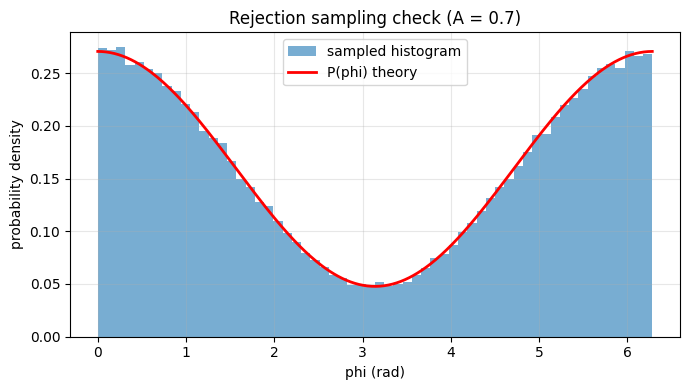

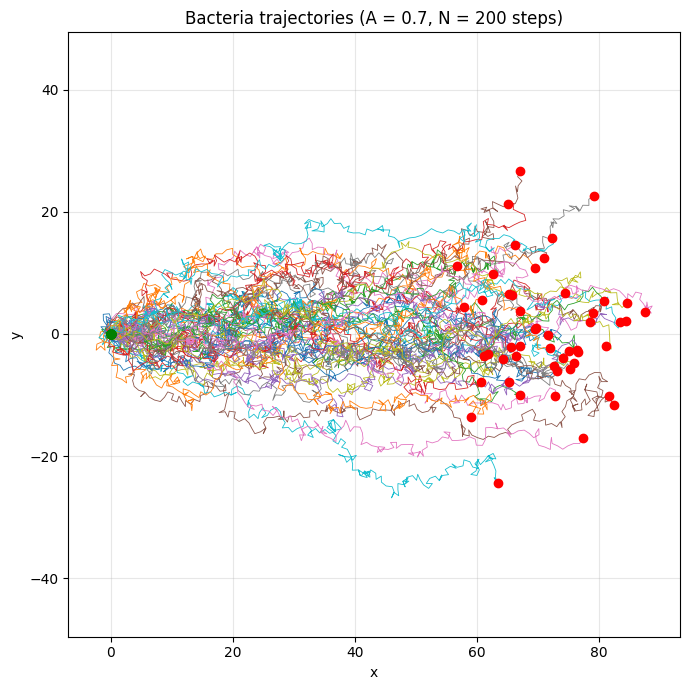

In [66]:
A = 0.7   # bias strength, 0 <= A <= 1
r = 1.0   # fixed step length
 
verify_sampling(A)
plot_trajectories(num_steps=200, num_bacteria=50, r=r, A=A)

------------------------------------

##### d) Prove that your MATLAB script reproduces equation: 

$$
\langle X\rangle = \frac{1}{2}ANr
$$

##### Vary A and N in your calculations.

In [67]:
# Same rejection-sampling algorithm as sample_phi, but drawing many angles at once.
 
def sample_phi_vec(A, size):
    """Rejection sampling of `size` angles from P(phi; A)."""
    p_max = (1.0 + A) / (2.0 * np.pi)
    out = np.empty(size) # create an empty array to hold the accepted samples
    filled = 0
    while filled < size:
        n = size - filled # n is the number of angles still needed
        phi = rng.uniform(0.0, 2.0 * np.pi, n)
        y = rng.uniform(0.0, p_max, n)
        accepted = phi[y <= probability_density(phi, A)]
        out[filled:filled + accepted.size] = accepted # fill the output array with accepted samples
        filled += accepted.size
    return out
 
 
def final_x(A, N, M, r):
    """Final x-position X of M independent bacteria, each taking N steps."""
    phi = sample_phi_vec(A, M * N).reshape(M, N)
    return (r * np.cos(phi)).sum(axis=1)
 
 
def measure(A, N, M, r):
    """Return (sample mean of X, standard error of the mean, theory 0.5*A*N*r)."""
    X = final_x(A, N, M, r)
    mean = X.mean()
    sem = X.std(ddof=1) / np.sqrt(M) # standard error of the mean
    theory = 0.5 * A * N * r
    return mean, sem, theory
 
 
def check_eq_2_5(r=1.0, M=4000, N_fixed=100,
                 A_values=None, N_values=None, A_list=(0.25, 0.5, 1.0)):
    """Vary A (fixed N) and vary N (several A); print table and plot."""
    if A_values is None:
        A_values = np.linspace(0.0, 1.0, 11)
    if N_values is None:
        N_values = np.array([10, 20, 50, 100, 200, 500, 1000])
 
    # Experiment 1: vary A at fixed N
    res1 = [measure(A, N_fixed, M, r) for A in A_values]

    # Experiment 2: vary N at several fixed A
    res2 = {A: [measure(A, N, M, r) for N in N_values] for A in A_list}
 
    # ---- table with z-scores: z = (sim - theory) / SEM ----
    print(f"Experiment 1: N = {N_fixed}, M = {M}")
    print(f"{'A':>5} {'<X> sim':>10} {'+/- SEM':>9} {'theory':>9} {'z':>6}")
    for A, (m, s, t) in zip(A_values, res1):
        print(f"{A:5.2f} {m:10.3f} {s:9.3f} {t:9.3f} {(m - t) / s:6.2f}")
 
    print(f"\nExperiment 2: M = {M}")
    print(f"{'A':>5} {'N':>6} {'<X> sim':>10} {'+/- SEM':>9} {'theory':>9} {'z':>6}")
    for A in A_list:
        for N, (m, s, t) in zip(N_values, res2[A]):
            print(f"{A:5.2f} {N:6d} {m:10.3f} {s:9.3f} {t:9.3f} {(m - t) / s:6.2f}")
 
    all_z = [(m - t) / s for (m, s, t) in res1] + \
            [(m - t) / s for A in A_list for (m, s, t) in res2[A]]
    print(f"\n|z| <= 2 for {np.mean(np.abs(all_z) <= 2) * 100:.0f}% of points "
          f"(expect ~95% if the simulation is unbiased)")
 
    # ---- figure ----
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
 
    m, s, _ = map(np.array, zip(*res1))
    Af = np.linspace(0, 1, 100)
    ax[0].plot(Af, 0.5 * Af * N_fixed * r, "k-", label=r"theory $\frac{1}{2}ANr$")
    ax[0].errorbar(A_values, m, yerr=s, fmt="o", capsize=3, label="simulation")
    ax[0].set(xlabel="A", ylabel=r"$\langle X\rangle$",
              title=f"Varying A (N = {N_fixed}, {M} bacteria)")
    ax[0].legend()
    ax[0].grid(alpha=0.3)
 
    Nf = np.linspace(0, np.max(N_values), 100)
    for A in A_list:
        m, s, _ = map(np.array, zip(*res2[A]))
        line, = ax[1].plot(Nf, 0.5 * A * Nf * r, "-", lw=1)
        ax[1].errorbar(N_values, m, yerr=s, fmt="o", capsize=3,
                       color=line.get_color(), label=f"A = {A}")
    ax[1].set(xlabel="N (steps)", ylabel=r"$\langle X\rangle$",
              title=f"Varying N ({M} bacteria); lines = theory")
    ax[1].legend()
    ax[1].grid(alpha=0.3)
 
    plt.tight_layout()
    # plt.savefig("check_eq_2_5.png", dpi=150)
    plt.show()


Experiment 1: N = 100, M = 4000
    A    <X> sim   +/- SEM    theory      z
 0.00      0.045     0.114     0.000   0.40
 0.10      5.066     0.113     5.000   0.59
 0.20      9.994     0.111    10.000  -0.06
 0.30     14.856     0.109    15.000  -1.32
 0.40     20.288     0.107    20.000   2.70
 0.50     24.871     0.103    25.000  -1.24
 0.60     30.029     0.100    30.000   0.29
 0.70     34.887     0.098    35.000  -1.15
 0.80     39.881     0.091    40.000  -1.30
 0.90     44.922     0.086    45.000  -0.91
 1.00     49.882     0.080    50.000  -1.47

Experiment 2: M = 4000
    A      N    <X> sim   +/- SEM    theory      z
 0.25     10      1.244     0.035     1.250  -0.18
 0.25     20      2.608     0.049     2.500   2.21
 0.25     50      6.261     0.079     6.250   0.13
 0.25    100     12.584     0.112    12.500   0.75
 0.25    200     24.904     0.154    25.000  -0.62
 0.25    500     62.520     0.245    62.500   0.08
 0.25   1000    124.948     0.355   125.000  -0.15
 0.50   

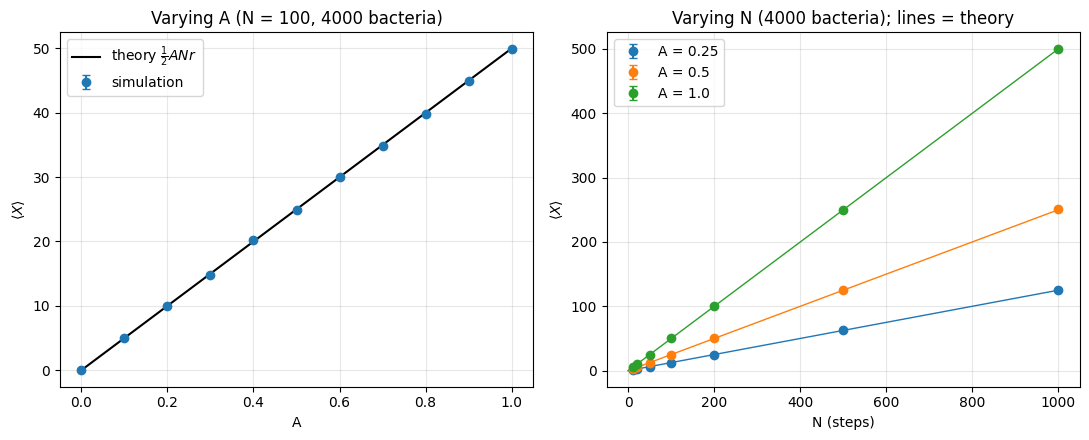

In [68]:
 # Part d)
check_eq_2_5(r=r, M=4000)

------------------------------------

##### f) Prove that your script reproduces equation 2.7. Vary N in your calculations.

$$
\newcommand{\avg}[1]{\left\langle #1 \right\rangle}
\avg{X^2} - \avg{X}^2 = \tfrac{1}{2} N r^2\left(1 - \tfrac{1}{2}A^2\right)\;
$$

##### Vary N in your calculations.

In [69]:
# Same data as part d): the final positions X of M independent bacteria.
# The sample variance of X (which already subtracts the mean, i.e. it
# estimates <X^2> - <X>^2) is compared with the theoretical value.
 
def measure_variance(A, N, M, r):
    """
    Return (sample variance of X, its standard error, theory).
 
    Standard error of a sample variance: sqrt((m4 - s^4) / M), where m4 is the
    fourth central moment of the data. This does not assume a Gaussian shape,
    which matters for small N where X is not yet close to Gaussian.
    """
    X = final_x(A, N, M, r)
    var = X.var(ddof=1)
    m4 = np.mean((X - X.mean()) ** 4)
    sem = np.sqrt((m4 - var ** 2) / M)
    theory = 0.5 * N * r ** 2 * (1.0 - 0.5 * A ** 2)
    return var, sem, theory
 
 
def check_eq_2_7(r=1.0, M=5000, N_values=None, A_list=(0.0, 0.5, 1.0)):
    """Vary N at several fixed A; print table and plot Var(X) vs N."""
    if N_values is None:
        N_values = np.array([10, 20, 50, 100, 200, 500, 1000])
 
    res = {A: [measure_variance(A, N, M, r) for N in N_values] for A in A_list}
 
    # ---- table with z-scores: z = (sim - theory) / SEM ----
    print(f"Check of Eq. 2.7, M = {M} bacteria per point")
    print(f"{'A':>5} {'N':>6} {'Var sim':>10} {'+/- SEM':>9} {'theory':>10} {'z':>6}")
    for A in A_list:
        for N, (v, s, t) in zip(N_values, res[A]):
            print(f"{A:5.2f} {N:6d} {v:10.3f} {s:9.3f} {t:10.3f} {(v - t) / s:6.2f}")
 
    all_z = [(v - t) / s for A in A_list for (v, s, t) in res[A]]
    print(f"\n|z| <= 2 for {np.mean(np.abs(all_z) <= 2) * 100:.0f}% of points "
          f"(expect ~95% if the simulation is unbiased)")
 
    # ---- figure ----
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
 
    Nf = np.linspace(0, np.max(N_values), 100)
    for A in A_list:
        v, s, t = map(np.array, zip(*res[A]))
        line, = ax[0].plot(Nf, 0.5 * Nf * r ** 2 * (1 - 0.5 * A ** 2), "-", lw=1)
        ax[0].errorbar(N_values, v, yerr=s, fmt="o", capsize=3,
                       color=line.get_color(), label=f"A = {A}")
        ax[1].errorbar(N_values, v / t, yerr=s / t, fmt="o", capsize=3,
                       color=line.get_color(), label=f"A = {A}")
 
    ax[0].set(xlabel="N (steps)",
              ylabel=r"$\langle X^2\rangle - \langle X\rangle^2$",
              title=f"Variance vs N ({M} bacteria); lines = theory")
    ax[0].legend()
    ax[0].grid(alpha=0.3)
 
    ax[1].axhline(1.0, color="k", lw=1)
    ax[1].set(xlabel="N (steps)", ylabel="simulation / theory",
              title="Ratio to Eq. 2.7 (should scatter around 1)",
              xscale="log")
    ax[1].legend()
    ax[1].grid(alpha=0.3)
 
    plt.tight_layout()
    plt.show()
 

Check of Eq. 2.7, M = 5000 bacteria per point
    A      N    Var sim   +/- SEM     theory      z
 0.00     10      5.006     0.099      5.000   0.06
 0.00     20      9.929     0.201     10.000  -0.35
 0.00     50     25.491     0.506     25.000   0.97
 0.00    100     49.884     0.988     50.000  -0.12
 0.00    200    101.229     1.953    100.000   0.63
 0.00    500    255.854     5.197    250.000   1.13
 0.00   1000    485.487     9.972    500.000  -1.46
 0.50     10      4.375     0.086      4.375  -0.00
 0.50     20      8.458     0.163      8.750  -1.79
 0.50     50     21.580     0.411     21.875  -0.72
 0.50    100     44.871     0.913     43.750   1.23
 0.50    200     88.127     1.729     87.500   0.36
 0.50    500    219.560     4.327    218.750   0.19
 0.50   1000    458.501     8.901    437.500   2.36
 1.00     10      2.515     0.049      2.500   0.31
 1.00     20      4.878     0.093      5.000  -1.32
 1.00     50     12.323     0.247     12.500  -0.72
 1.00    100     2

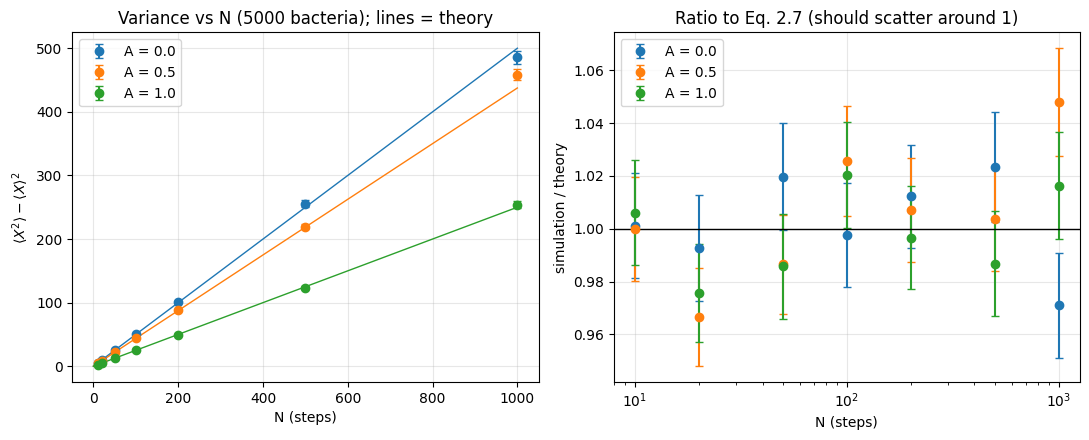

In [71]:
r = 1.0   # fixed step length
A = 0.7   # bias strength for the part b) plots, 0 <= A <= 1

check_eq_2_7(r=r, M=5000)

------------------------------------

##### g) Rewrite your program such that it makes use of importance sampling. Prove that the efficiency (ratio between number accepted trials and total number of trials) has been improved, while the results are still correct.